# 03. Does the population coupling depend on the density estimator? (Austria)

**Question.** Notebooks 01 and 02 mark the SP nodes with a k-NN local density. A
fixed-radius count is an equally natural estimator. Do both give the same coupling?

**Data.** Austria cities (N = 2253, real populations). The raw data are not distributed with this repository, the outputs are kept.
**Output.** `out/03_estimator_comparison_austria_cities.csv`.
**Paper.** Not in the current version.
**Code.** `src/metadata_marks.py`.

**Design.** Populations are given by rank matching with each estimator. Both markings
then carry exactly the real population distribution, and only differ by which node gets
which value. Any gap in M_norm(r) or in the people 2PCF comes from the estimator.
The notebook runs on any dataset with a population mark (`DATASET_NAME`).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

ROOT = Path.cwd().resolve().parent.parent           # repository root
sys.path.insert(0, str(ROOT / "src"))
import synthesis_utils as su
import metadata_marks as mm

# Okabe-Ito palette, one colour per ESTIMATOR (both cases share the same rank
# matching, so the colour encodes the estimator, not the mapping).
C = {"data": "#000000", "knn": "#0072B2", "rad": "#D55E00",
     "null": "#999999", "poisson": "#009E73"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 10})

DATASET_NAME = "Austria Cities"
# Datasets compared in the primacy test (section 6). Only datasets with a real city
# population make sense here (datasets with a population mark).
PRIMACY_DATASETS = [DATASET_NAME]

ds = su.DATASETS[DATASET_NAME]
ld = su.load_dataset(ds)
xy_data, pop_data, geom = ld["xy_norm"], ld["pop_data"], ld["geom_norm"]
print(f"{DATASET_NAME}: N={ld['N_real']}, scale={ld['scale_m']/1e3:.0f} km")
print(f"  population min/median/max = {pop_data.min():.0f} / "
      f"{np.median(pop_data):.0f} / {pop_data.max():.0f}")
print(f"  share of the largest city = {100*pop_data.max()/pop_data.sum():.1f} %")
print(f"  gamma of the nodes = {ld['gamma_fit']:.3f}")

# The generative cloud: calibrated SP mixture (fractal + random background)
xy_sp = su.build_sp_mixture(ds, ld["gdf_edge"], ld["bounds"], geom,
                            ld["r_data"], ld["xi_data"],
                            N_target=ld["N_real"], seed=su.SEED)
print(f"  SP mixture: {len(xy_sp)} nodes")

  N=2,253  scale=572.9 km


  gamma_data=0.494  r0_norm=0.00116
Austria Cities: N=2253, scale=573 km
  population min/median/max = 7 / 1544 / 2223236
  share of the largest city = 24.6 %
  gamma of the nodes = 0.494


  SP mixture: 2253 nodes


## 1. Two local density estimators

- **k-NN**: ρ_k(i) = k / (π d_k(i)²), k = 10. Continuous, with a radius that adapts to
  the local density.
- **Fixed-radius count**: number of neighbours within h, the median 10-NN distance.
  Integer, hence many ties.

Rank matching only uses the ranking, so the agreement is measured with a Spearman
correlation.

radius h = 0.0195 (normalised) = 11.2 km
Spearman(k-NN, radius) = 0.955   <- the two estimators seem to agree
ties: k-NN 120/2253 (5%) | radius 2202/2253 (98%)
distinct values: k-NN 2133 | radius 51


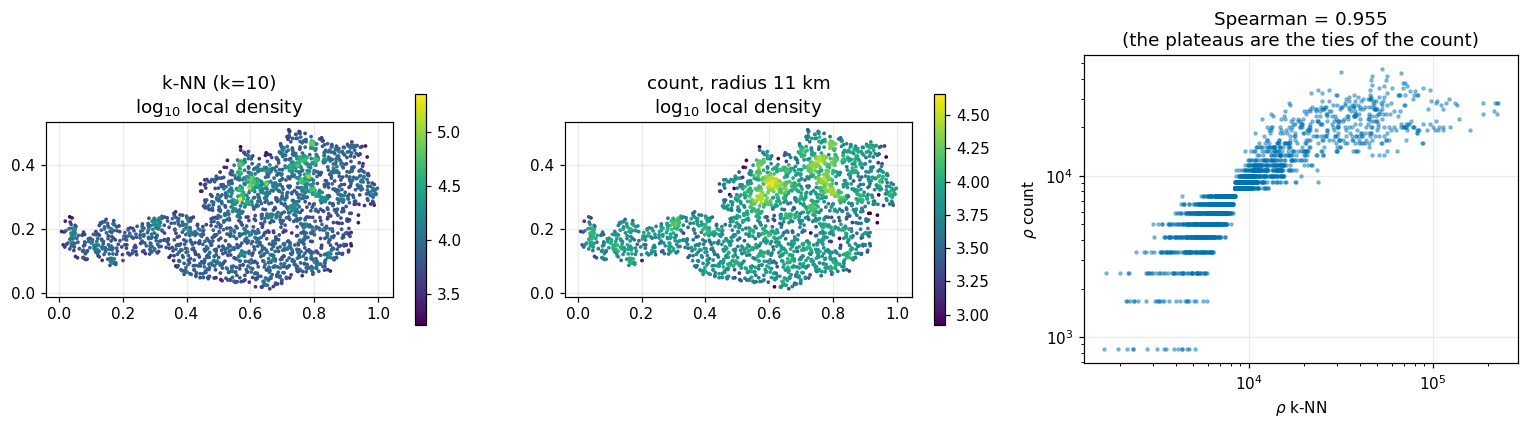

In [2]:
K_NN = 10
rho_knn = mm.local_density_knn(xy_sp, k=K_NN)
h = mm.default_radius(xy_sp, k=K_NN)
rho_rad = mm.local_density_radius(xy_sp, h)

rs = spearmanr(rho_knn, rho_rad).statistic
ties = lambda r: len(r) - len(np.unique(r))
print(f"radius h = {h:.4f} (normalised) = {h * ld['scale_m'] / 1e3:.1f} km")
print(f"Spearman(k-NN, radius) = {rs:.3f}   <- the two estimators seem to agree")
print(f"ties: k-NN {ties(rho_knn)}/{len(rho_knn)} "
      f"({100*ties(rho_knn)/len(rho_knn):.0f}%) | "
      f"radius {ties(rho_rad)}/{len(rho_rad)} ({100*ties(rho_rad)/len(rho_rad):.0f}%)")
print(f"distinct values: k-NN {len(np.unique(rho_knn))} | radius {len(np.unique(rho_rad))}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, rho, ttl in [(axes[0], rho_knn, f"k-NN (k={K_NN})"),
                     (axes[1], rho_rad, f"count, radius {h*ld['scale_m']/1e3:.0f} km")]:
    sc = ax.scatter(*xy_sp.T, s=6, c=np.log10(np.maximum(rho, rho[rho > 0].min())),
                    cmap="viridis", lw=0)
    ax.set_aspect("equal"); ax.set_title(f"{ttl}\nlog$_{{10}}$ local density")
    fig.colorbar(sc, ax=ax, shrink=0.75)
axes[2].loglog(rho_knn, np.maximum(rho_rad, rho_rad[rho_rad > 0].min()),
               ".", ms=4, alpha=0.4, c=C["knn"])
axes[2].set_xlabel("$\\rho$ k-NN"); axes[2].set_ylabel("$\\rho$ count")
axes[2].set_title(f"Spearman = {rs:.3f}\n(the plateaus are the ties of the count)")
fig.tight_layout(); plt.show()

## 2. Rank matching

The largest population goes to the densest node, and so on. Check: the Zipf exponent is
the one of the data with both estimators.

Check: is the population distribution identical?
  Zipf: data 1.020 | k-NN 1.020 | radius 1.020
  same population values: True (k-NN), True (radius)

But the two markings differ: Spearman(pop_knn, pop_rad) = 0.953
  nodes receiving a different population: 2249 / 2253


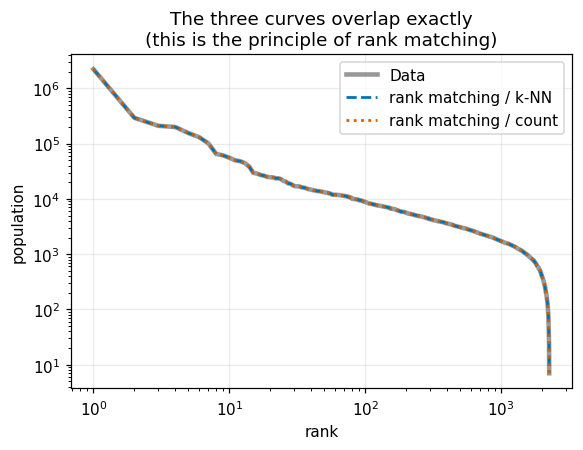

In [3]:
pop_knn = mm.pop_rank_matching(rho_knn, pop_data)   # marking from k-NN
pop_rad = mm.pop_rank_matching(rho_rad, pop_data)   # marking from the count

print("Check: is the population distribution identical?")
print(f"  Zipf: data {su.fit_zipf_exponent(pop_data):.3f} | "
      f"k-NN {su.fit_zipf_exponent(pop_knn):.3f} | radius {su.fit_zipf_exponent(pop_rad):.3f}")
print(f"  same population values: "
      f"{np.array_equal(np.sort(pop_knn), np.sort(pop_data))} (k-NN), "
      f"{np.array_equal(np.sort(pop_rad), np.sort(pop_data))} (radius)")
print(f"\nBut the two markings differ: Spearman(pop_knn, pop_rad) = "
      f"{spearmanr(pop_knn, pop_rad).statistic:.3f}")
print(f"  nodes receiving a different population: "
      f"{(pop_knn != pop_rad).sum()} / {len(pop_knn)}")

def ranksize(p):
    p = np.sort(np.asarray(p))[::-1]
    return np.arange(1, len(p) + 1), p

fig, ax = plt.subplots(figsize=(5.4, 4.2))
ax.loglog(*ranksize(pop_data), "-", c=C["data"], lw=3, alpha=0.4, label="Data")
ax.loglog(*ranksize(pop_knn), "--", c=C["knn"], lw=1.8, label="rank matching / k-NN")
ax.loglog(*ranksize(pop_rad), ":", c=C["rad"], lw=1.8, label="rank matching / count")
ax.set_xlabel("rank"); ax.set_ylabel("population")
ax.set_title("The three curves overlap exactly\n(this is the principle of rank matching)")
ax.legend(); fig.tight_layout(); plt.show()

## 3. Maps of the three markings

Same list of populations, only the receiving node changes.

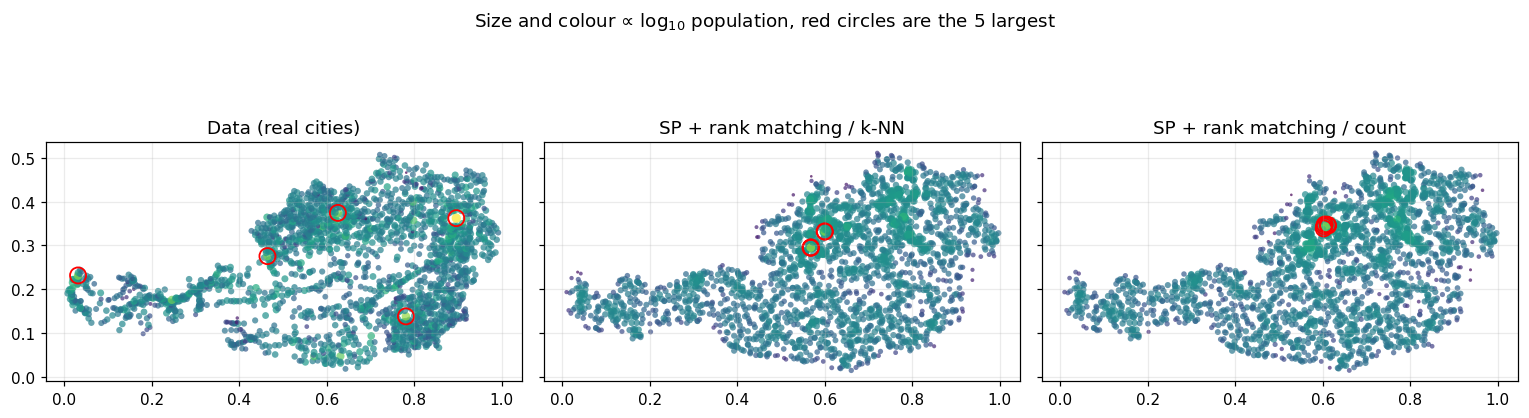

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharex=True, sharey=True)
for ax, xy, p, ttl in [(axes[0], xy_data, pop_data, "Data (real cities)"),
                       (axes[1], xy_sp, pop_knn, "SP + rank matching / k-NN"),
                       (axes[2], xy_sp, pop_rad, "SP + rank matching / count")]:
    lp = np.log10(p)
    s = 3 + 34 * (lp - lp.min()) / (lp.max() - lp.min())
    ax.scatter(*xy.T, s=s, c=lp, cmap="viridis", alpha=0.7, lw=0)
    top = np.argsort(p)[::-1][:5]
    ax.scatter(*xy[top].T, s=110, facecolors="none", edgecolors="red", lw=1.2)
    ax.set_aspect("equal"); ax.set_title(ttl)
fig.suptitle("Size and colour ∝ log$_{10}$ population, red circles are the 5 largest")
fig.tight_layout(); plt.show()

## 4. M(r) and M_norm(r)

Definitions in notebook 02. M_norm = 1 without coupling, > 1 when large populations are
close to each other. The null (grey band) is the mean ± σ over 30 permutations of the
marks, because one permutation is dominated by where the largest city lands.

case                                D_M   M_norm at peak
Data                               2.13    1.16 at r=0.0425 (24.3 km)
SP + rank matching / k-NN          1.28    6.99 at r=0.0026 (1.5 km)
SP + rank matching / count         1.68    2.79 at r=0.0153 (8.8 km)
Data, shuffled marks               2.09    1.00 at r=0.0912 (52.3 km)
Poisson + data marks               2.01    1.01 at r=0.0119 (6.8 km)

D_M:    data 2.134 vs null 1.952 ± 0.134  -> 1.4 sigma (not discriminant, as expected)
M_norm: null flat at 1.04


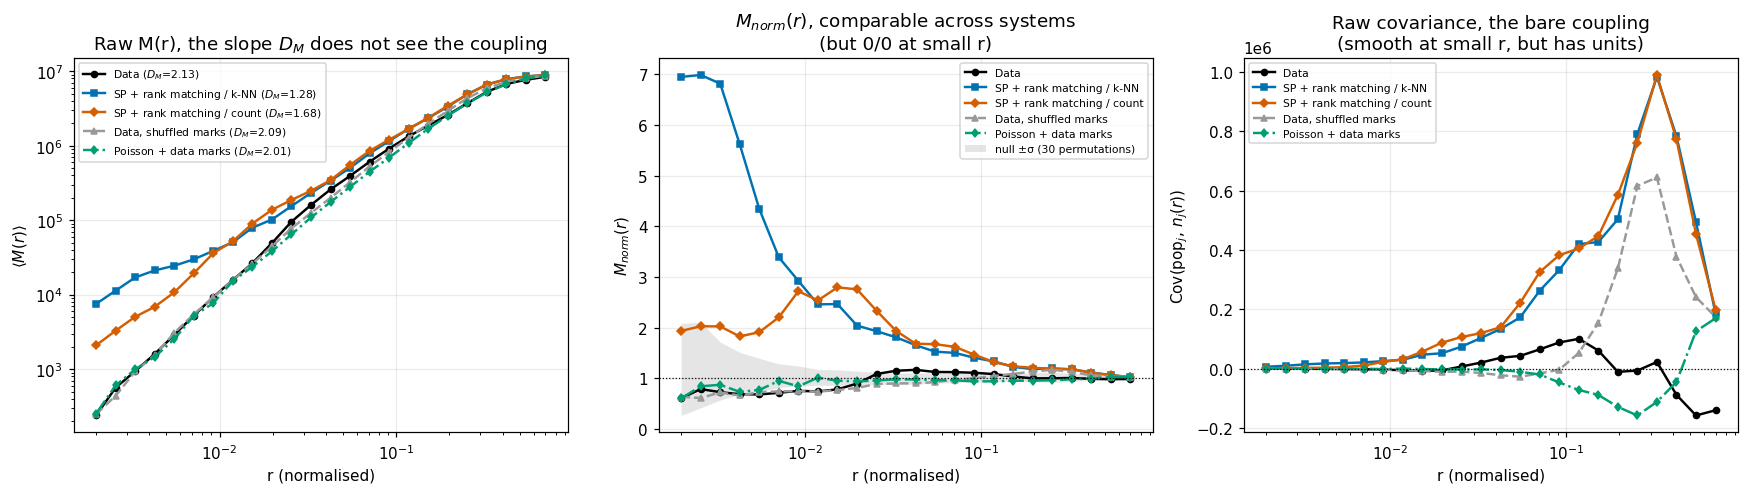

In [5]:
r_grid = np.logspace(np.log10(2e-3), np.log10(0.7), 24)
xy_pois = su.simulate_poisson(len(xy_data), geom, seed=1)
rng = np.random.default_rng(0)

cases = {
    "Data":                       (xy_data, pop_data,                  C["data"], "o-"),
    "SP + rank matching / k-NN":  (xy_sp,   pop_knn,                   C["knn"],  "s-"),
    "SP + rank matching / count": (xy_sp,   pop_rad,                   C["rad"],  "D-"),
    "Data, shuffled marks":       (xy_data, rng.permutation(pop_data), C["null"], "^--"),
    "Poisson + data marks":       (xy_pois, pop_data,                  C["poisson"], "d-."),
}
M_prof, M_norm, COV, DM, pk = {}, {}, {}, {}, {}
for k, (xy, p, *_) in cases.items():
    mn, M, N = mm.normalized_population_profile(xy, p, r_grid)
    M_prof[k], M_norm[k] = M, mn
    COV[k] = mm.covariance_profile(M, N, p)      # raw coupling, not normalised
    DM[k] = mm.mass_dimension(r_grid, M, a=1, b=16)
    i = int(np.nanargmax(mn[1:16]) + 1)
    pk[k] = (float(mn[i]), float(r_grid[i]))

null_m, null_s, dm_null, dm_null_s = mm.shuffled_null_profile(
    xy_data, pop_data, r_grid, n_shuffle=30, seed=0)

print(f"{'case':32s} {'D_M':>6s}   M_norm at peak")
for k in cases:
    print(f"{k:32s} {DM[k]:6.2f}   {pk[k][0]:5.2f} at r={pk[k][1]:.4f} "
          f"({pk[k][1]*ld['scale_m']/1e3:.1f} km)")
print(f"\nD_M:    data {DM['Data']:.3f} vs null {dm_null:.3f} ± {dm_null_s:.3f}"
      f"  -> {abs(DM['Data']-dm_null)/dm_null_s:.1f} sigma (not discriminant, as expected)")
print(f"M_norm: null flat at {np.nanmean(null_m):.2f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
for k, (xy, p, c, st) in cases.items():
    axes[0].loglog(r_grid, M_prof[k], st, ms=4, c=c, lw=1.6,
                   label=f"{k} ($D_M$={DM[k]:.2f})")
    axes[1].semilogx(r_grid, M_norm[k], st, ms=4, c=c, lw=1.6, label=k)
    axes[2].semilogx(r_grid, COV[k], st, ms=4, c=c, lw=1.6, label=k)
axes[0].set_xlabel("r (normalised)")
axes[0].set_ylabel("$\\langle M(r) \\rangle$")
axes[0].set_title("Raw M(r), the slope $D_M$ does not see the coupling")
axes[0].legend(fontsize=7)

axes[1].fill_between(r_grid, null_m - null_s, null_m + null_s, color=C["null"],
                     alpha=0.25, lw=0, label="null ±σ (30 permutations)")
axes[1].axhline(1, c="k", lw=0.8, ls=":")
axes[1].set_xlabel("r (normalised)")
axes[1].set_ylabel("$M_{norm}(r)$")
axes[1].set_title("$M_{norm}(r)$, comparable across systems\n(but 0/0 at small r)")
axes[1].legend(fontsize=7)

axes[2].axhline(0, c="k", lw=0.8, ls=":")
axes[2].set_xlabel("r (normalised)")
axes[2].set_ylabel("$\\mathrm{Cov}(\\mathrm{pop}_j,\\, n_j(r))$")
axes[2].set_title("Raw covariance, the bare coupling\n(smooth at small r, but has units)")
axes[2].legend(fontsize=7)
fig.tight_layout(); plt.show()

### Check: ties of the count

Ties are broken by index order in `pop_rank_matching`. We break them at random 10 times.

In [6]:
peaks_tie = []
for s_ in range(10):
    perm = np.random.default_rng(100 + s_).permutation(len(rho_rad))
    p_perm = np.empty(len(rho_rad))
    p_perm[perm] = mm.pop_rank_matching(rho_rad[perm], pop_data)
    mn_, _, _ = mm.normalized_population_profile(xy_sp, p_perm, r_grid)
    peaks_tie.append(float(np.nanmax(mn_[1:16])))
print(f"M_norm peak, count with ties broken by index : {pk['SP + rank matching / count'][0]:.3f}")
print(f"M_norm peak, count with ties broken at random: "
      f"{np.mean(peaks_tie):.3f} ± {np.std(peaks_tie):.3f} (10 draws)")

M_norm peak, count with ties broken by index : 2.793
M_norm peak, count with ties broken at random: 2.792 ± 0.002 (10 draws)


## 5. People 2PCF

Pairs weighted by the product of the populations (notebook 02).

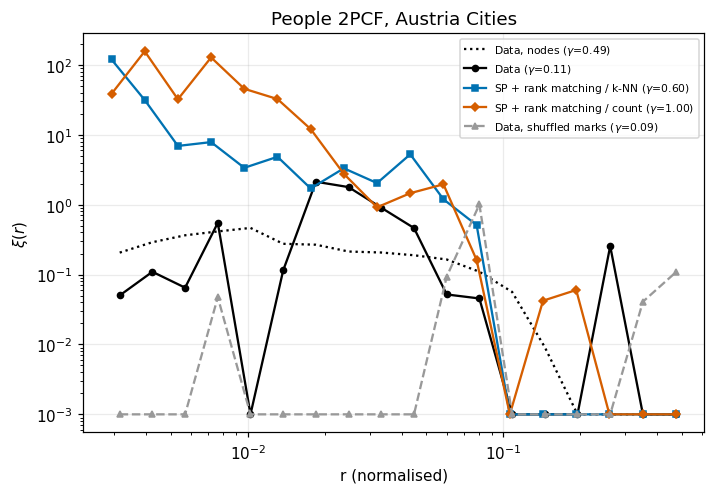

gamma of the nodes (data)        : 0.494
gamma_people, Data                           : 0.114
gamma_people, SP + rank matching / k-NN      : 0.598
gamma_people, SP + rank matching / count     : 0.996
gamma_people, Data, shuffled marks           : 0.092


In [7]:
people = {}
for k in cases:
    if k == "Poisson + data marks":
        continue                                  # not informative here
    xy, p, *_ = cases[k]
    people[k] = mm.compute_2pcf_people(xy, p, geom)

fig, ax = plt.subplots(figsize=(6.6, 4.6))
ax.loglog(ld["r_data"], np.clip(ld["xi_data"], 1e-3, None), ":", c=C["data"],
          lw=1.5, label=f"Data, nodes ($\\gamma$={ld['gamma_fit']:.2f})")
gammas = {}
for k, (r, xi) in people.items():
    g, _ = su.fit_powerlaw_norm(r, xi)
    gammas[k] = g
    _, _, c, st = cases[k]
    ax.loglog(r, np.clip(xi, 1e-3, None), st, ms=4, c=c,
              label=f"{k} ($\\gamma$={g:.2f})" if g is not None else k)
ax.set_xlabel("r (normalised)"); ax.set_ylabel("$\\xi(r)$")
ax.set_title(f"People 2PCF, {DATASET_NAME}")
ax.legend(fontsize=7); fig.tight_layout(); plt.show()

print(f"gamma of the nodes (data)        : {ld['gamma_fit']:.3f}")
for k, g in gammas.items():
    print(f"gamma_people, {k:30s} : {g:.3f}")

## 6. Weight of the largest cities

The people 2PCF weights each pair by p_i p_j, so a city that is much larger than the
rank-size law predicts (a primate city) can dominate it. We compute the usual primacy
indices (P₁/P₂, P₁/(P₁+…+P₄), share of P₁, observed over predicted P₁ from a rank-size
fit on ranks 2 to 50), then remove the n largest cities (n = 1, 5, 20) and fit again.
If γ_people moves to γ_nodes, the gap was carried by the top of the distribution.
A central city surrounded by large ones steepens the curve, an isolated one flattens it.

                                    Austria Cities
P1/P2 (two-city index)                        7.60
P1/(P1+P2+P3+P4)                              0.76
share of P1 in total (%)                      24.6
Zipf exponent                                 1.02
observed P1 / predicted P1                    3.55
weight of pairs with P1 (%)                   39.6

gamma_people, all                            0.114
without top-1                                0.534
without top-5                                0.601
without top-20                               0.607
gamma_nodes                                  0.494


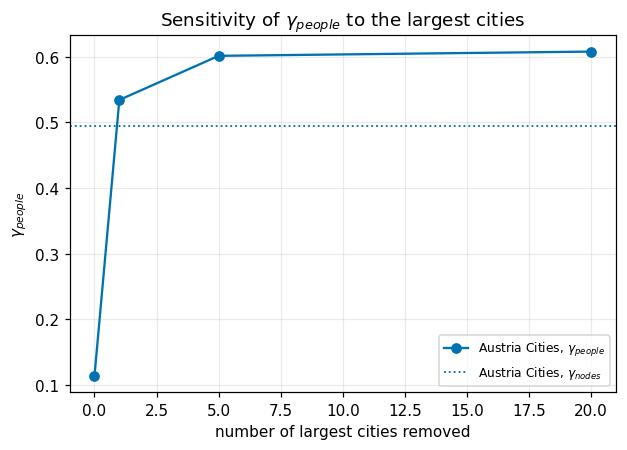

In [8]:
# Primacy indices and weight of the pairs involving P1 in xi_people
prim, res_drop = {}, {}
for name in PRIMACY_DATASETS:
    ld_i = ld if name == DATASET_NAME else su.load_dataset(su.DATASETS[name], verbose=False)
    p = np.sort(ld_i["pop_data"])[::-1]
    # P1 predicted by the rank-size law fitted WITHOUT it (ranks 2..50)
    coef = np.polyfit(np.log(np.arange(2, 51)), np.log(p[1:50]), 1)
    p1_pred = np.exp(np.polyval(coef, np.log(1)))
    # weight of the pairs involving P1 in xi_people (weights p_i*p_j)
    w_tot = p.sum()**2 - (p**2).sum()          # = sum of p_i*p_j over i != j
    w_p1 = 2 * p[0] * p[1:].sum()
    prim[name] = dict(p1_p2=p[0]/p[1], p1_4=p[0]/p[:4].sum(),
                      share=100*p[0]/p.sum(), zipf=su.fit_zipf_exponent(p),
                      ratio_pred=p[0]/p1_pred, w_p1=100*w_p1/w_tot)

    # Removal of the n largest cities
    p_i, xy_i, geom_i = ld_i["pop_data"], ld_i["xy_norm"], ld_i["geom_norm"]
    vals = {}
    for drop in (0, 1, 5, 20):
        keep = np.argsort(p_i)[::-1][drop:]
        r_i, xi_i = mm.compute_2pcf_people(xy_i[keep], p_i[keep], geom_i)
        vals[drop], _ = su.fit_powerlaw_norm(r_i, xi_i)
    vals["gamma_nodes"] = ld_i["gamma_fit"]
    res_drop[name] = vals

print(f"{'':32s}" + "".join(f"{n:>18s}" for n in PRIMACY_DATASETS))
for k, lbl, f in [("p1_p2", "P1/P2 (two-city index)", "{:18.2f}"),
                  ("p1_4", "P1/(P1+P2+P3+P4)", "{:18.2f}"),
                  ("share", "share of P1 in total (%)", "{:18.1f}"),
                  ("zipf", "Zipf exponent", "{:18.2f}"),
                  ("ratio_pred", "observed P1 / predicted P1", "{:18.2f}"),
                  ("w_p1", "weight of pairs with P1 (%)", "{:18.1f}")]:
    print(f"{lbl:32s}" + "".join(f.format(prim[n][k]) for n in PRIMACY_DATASETS))
print()
for drop, lbl in [(0, "gamma_people, all"), (1, "without top-1"),
                  (5, "without top-5"), (20, "without top-20"),
                  ("gamma_nodes", "gamma_nodes")]:
    print(f"{lbl:32s}" + "".join(f"{res_drop[n][drop]:18.3f}" for n in PRIMACY_DATASETS))

fig, ax = plt.subplots(figsize=(5.8, 4.2))
drops = [0, 1, 5, 20]
for name, c in zip(PRIMACY_DATASETS, [C["knn"], C["rad"], C["poisson"], C["null"]]):
    ax.plot(drops, [res_drop[name][d] for d in drops], "o-", c=c,
            label=f"{name}, $\\gamma_{{people}}$")
    ax.axhline(res_drop[name]["gamma_nodes"], c=c, ls=":", lw=1.2,
               label=f"{name}, $\\gamma_{{nodes}}$")
ax.set_xlabel("number of largest cities removed")
ax.set_ylabel("$\\gamma_{people}$")
ax.set_title("Sensitivity of $\\gamma_{people}$ to the largest cities")
ax.legend(fontsize=8); fig.tight_layout(); plt.show()

In [9]:
rows = []
for k in cases:
    rows.append(dict(observable="D_M [not discriminant]", case=k, value=round(DM[k], 3)))
for k in cases:
    rows.append(dict(observable="M_norm at peak (1 = no coupling)", case=k,
                     value=round(pk[k][0], 3)))
for k, g in gammas.items():
    rows.append(dict(observable="gamma_people", case=k,
                     value=(round(g, 3) if g is not None else None)))
rows.append(dict(observable="gamma_nodes", case="Data",
                 value=round(ld["gamma_fit"], 3)))
df = pd.DataFrame(rows)
slug = DATASET_NAME.lower().replace(" ", "_")
out_csv = ROOT / "out" / f"03_estimator_comparison_{slug}.csv"
df.to_csv(out_csv, index=False)
print(df.to_string(index=False))
print("->", out_csv)

                      observable                       case  value
          D_M [not discriminant]                       Data  2.134
          D_M [not discriminant]  SP + rank matching / k-NN  1.281
          D_M [not discriminant] SP + rank matching / count  1.680
          D_M [not discriminant]       Data, shuffled marks  2.089
          D_M [not discriminant]       Poisson + data marks  2.012
M_norm at peak (1 = no coupling)                       Data  1.165
M_norm at peak (1 = no coupling)  SP + rank matching / k-NN  6.989
M_norm at peak (1 = no coupling) SP + rank matching / count  2.793
M_norm at peak (1 = no coupling)       Data, shuffled marks  0.996
M_norm at peak (1 = no coupling)       Poisson + data marks  1.010
                    gamma_people                       Data  0.114
                    gamma_people  SP + rank matching / k-NN  0.598
                    gamma_people SP + rank matching / count  0.996
                    gamma_people       Data, shuffled marks  0

## Results (Austria)

| | M_norm peak | γ_people |
|---|---|---|
| data | 1.16 (r ≈ 24 km) | 0.11 (nodes: 0.49) |
| SP, rank matching / k-NN | 6.99 | 0.60 |
| SP, rank matching / count | 2.79 | 1.00 |
| null, shuffled marks | 1.00 | 0.09 |

- Spearman between the estimators is 0.955, yet M_norm differs by a factor 2.5 between
  them. Breaking the ties at random does not change it (2.79 ± 0.002).
- The coupling of the data is weak (M_norm peak 1.16, null at 1.04). The SP over-couples
  with both estimators, much more than on Belgium.
- Vienna dominates. It holds 24.6 % of the population and 39.6 % of the pair weight
  (P₁/P₂ = 7.6, observed over predicted P₁ = 3.55). It lies at the eastern border, far
  from the other large cities, so it flattens the people 2PCF (γ_people = 0.11, below
  γ_nodes). Without Vienna, γ_people = 0.53, close to γ_nodes = 0.49, and it stays near
  0.60 without the 5 or 20 largest cities.
- The two countries give opposite effects of the primate city (steeper in Belgium,
  flatter in Austria). γ_people mostly reflects the position of the largest city.